In [1]:
import common as cm
import os
import pandas as pd
import numpy as np

# Construct pmatrix and bmatrix

In [2]:
### Read full AUC matrices (rows = target ICD, columns = "<candidate ICD>_<method>") ###
aou_full_auc_matrix = pd.read_csv(os.path.join(cm.ROOT_PATH, "result", "auc_landscape", "aou_auc_landscape_full_matrix.csv"), index_col=0)
ukb_full_auc_matrix = pd.read_csv(os.path.join(cm.ROOT_PATH, "result", "auc_landscape", "ukb_auc_landscape_full_matrix.csv"), index_col=0)

### Collapse three PRS methods per candidate disease by max AUC ###
cand_disease = aou_full_auc_matrix.columns.str.rsplit("_", n=1).str[0]
aou_auc_max = aou_full_auc_matrix.T.groupby(cand_disease, sort=False).max().T

cand_disease = ukb_full_auc_matrix.columns.str.rsplit("_", n=1).str[0]
ukb_auc_max = ukb_full_auc_matrix.T.groupby(cand_disease, sort=False).max().T

### Overlap diseases: present as target (row) and candidate (column) in both cohorts ###
overlap_icd = sorted(
    set(aou_auc_max.index) & set(aou_auc_max.columns)
    & set(ukb_auc_max.index) & set(ukb_auc_max.columns)
)
print("Overlap diseases:", len(overlap_icd))

### Restrict both cohorts to the same target x candidate set BEFORE ranking ###
aou_auc_max = aou_auc_max.loc[overlap_icd, overlap_icd]
ukb_auc_max = ukb_auc_max.loc[overlap_icd, overlap_icd]

### AoU: rank weight within overlap set (rank 1 -> 10, rank 10 -> 1, others -> 0) ###
row_rank = aou_auc_max.rank(axis=1, ascending=False, method="first")
n_top = row_rank.max(axis=1).clip(upper=10)
aou_pmatrix = (row_rank.rsub(n_top + 1, axis=0)).where(row_rank <= 10, 0).fillna(0).astype(int)

### UKB: rank weight within overlap set ###
row_rank = ukb_auc_max.rank(axis=1, ascending=False, method="first")
n_top = row_rank.max(axis=1).clip(upper=10)
ukb_pmatrix = (row_rank.rsub(n_top + 1, axis=0)).where(row_rank <= 10, 0).fillna(0).astype(int)

### Binary Top-10 matrices for hub score ###
aou_bmatrix = (aou_pmatrix > 0).astype(int)
ukb_bmatrix = (ukb_pmatrix > 0).astype(int)

### Sanity check: identical square shape, identical row/column order, 10 selections per row ###
print(aou_pmatrix.shape, ukb_pmatrix.shape)
print((aou_pmatrix.index == ukb_pmatrix.index).all(), (aou_pmatrix.columns == ukb_pmatrix.columns).all())
print((aou_bmatrix.sum(axis=1) == 10).all(), (ukb_bmatrix.sum(axis=1) == 10).all())

Overlap diseases: 368
(368, 368) (368, 368)
True True
True True


# (b) matrix similarity

Observed mean shared = 4.00/10
Uniform null = 0.27, fold = 14.7x, p = 1.0e-03
Hub-preserving null = 0.93, fold = 4.3x, p = 1.0e-03


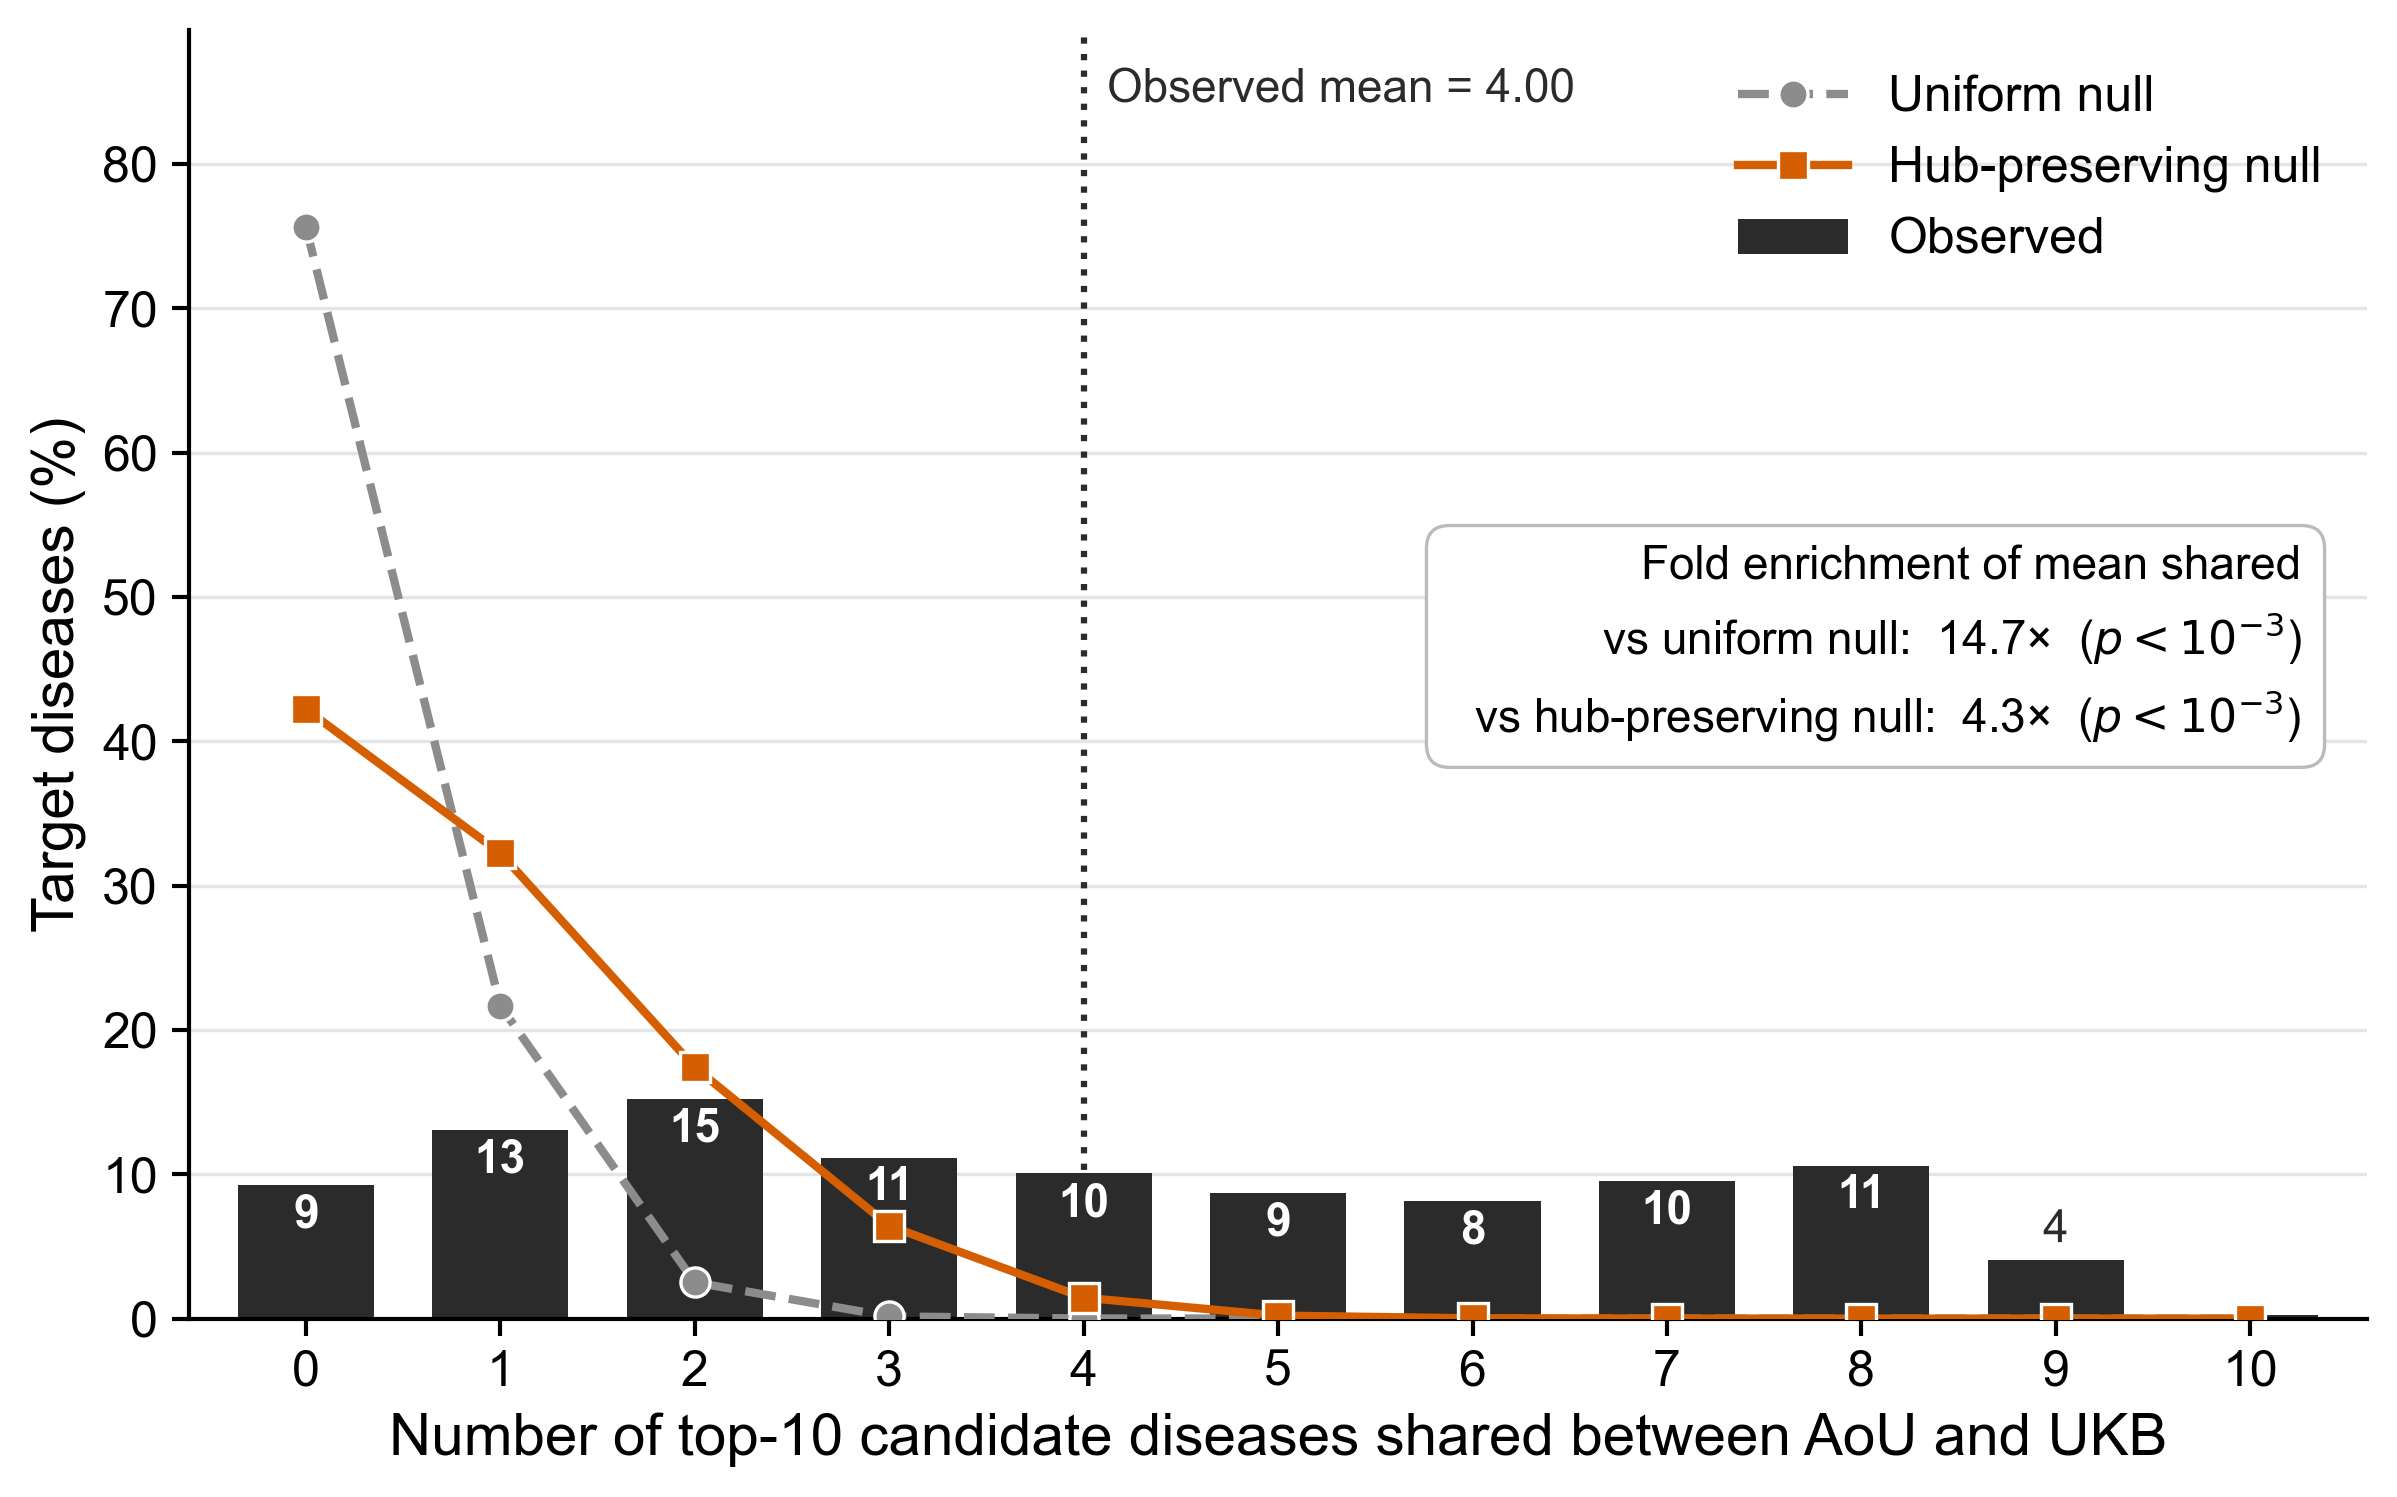

In [3]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from scipy.stats import hypergeom
import matplotlib.patheffects as pe

### Publication style: Arial 7 pt, thin axes ###
matplotlib.rcParams.update({
    "font.family": "Arial", "font.size": 7, "axes.linewidth": 0.6,
    "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.major.size": 2.5, "ytick.major.size": 2.5, "pdf.fonttype": 42,
})

### Inputs: binary top-10 matrices on the shared overlap set (same rows/cols, same order) ###
aou_arr = np.asarray(aou_bmatrix).astype(bool)
ukb_arr = np.asarray(ukb_bmatrix).astype(bool)
n_target, n_candidate = aou_arr.shape
top_k = 10
n_perm = 1000
rng = np.random.default_rng(42)
k_grid = np.arange(0, top_k + 1)

### Observed: number of shared top-10 candidates per target (0..10) ###
obs_shared = (aou_arr & ukb_arr).sum(axis=1)
obs_mean = obs_shared.mean()
obs_pmf = np.bincount(obs_shared, minlength=top_k + 1) / n_target

### Null A (uniform): UKB top-10 drawn uniformly at random -> hypergeometric ###
null_uniform_pmf = hypergeom(M=n_candidate, n=top_k, N=top_k).pmf(k_grid)
null_uniform_means = rng.hypergeometric(top_k, n_candidate - top_k, top_k, size=(n_perm, n_target)).mean(axis=1)

### Null B (hub-preserving): keep AoU selections fixed; redraw each UKB top-10 with ###
### probability proportional to each candidate's UKB selection frequency (Gumbel top-k) ###
ukb_freq = ukb_arr.sum(axis=0).astype(float) + 0.5          # +0.5 so unselected candidates keep tiny mass
log_p = np.log(ukb_freq / ukb_freq.sum())
null_hub_means = np.empty(n_perm)
null_hub_counts = np.zeros(top_k + 1)
for p in range(n_perm):
    # Gumbel-max trick: top-k of (log p + Gumbel noise) = weighted sampling without replacement
    keys = log_p[None, :] + rng.gumbel(size=(n_target, n_candidate))
    sel = np.argpartition(-keys, top_k, axis=1)[:, :top_k]
    ukb_perm = np.zeros_like(ukb_arr)
    np.put_along_axis(ukb_perm, sel, True, axis=1)
    shared_p = (aou_arr & ukb_perm).sum(axis=1)
    null_hub_means[p] = shared_p.mean()
    null_hub_counts += np.bincount(shared_p, minlength=top_k + 1)
null_hub_pmf = null_hub_counts / null_hub_counts.sum()

### Fold enrichment and empirical p values against both nulls ###
fold_uniform = obs_mean / null_uniform_means.mean()
fold_hub     = obs_mean / null_hub_means.mean()
p_uniform = (np.sum(null_uniform_means >= obs_mean) + 1) / (n_perm + 1)
p_hub     = (np.sum(null_hub_means >= obs_mean) + 1) / (n_perm + 1)
print(f"Observed mean shared = {obs_mean:.2f}/10")
print(f"Uniform null = {null_uniform_means.mean():.2f}, fold = {fold_uniform:.1f}x, p = {p_uniform:.1e}")
print(f"Hub-preserving null = {null_hub_means.mean():.2f}, fold = {fold_hub:.1f}x, p = {p_hub:.1e}")

### p-value text in mathtext power-of-ten form (no "e" notation) ###
p_floor = 1 / (n_perm + 1)
floor_exp = int(np.ceil(np.log10(p_floor)))          # 1/1001 -> -3, so text reads p < 10^-3

# Uniform null: upper bound if no permutation reached observed, else a x 10^b
if p_uniform <= p_floor:
    p_uni_txt = rf"$p < 10^{{{floor_exp}}}$"
else:
    b = int(np.floor(np.log10(p_uniform)))
    p_uni_txt = rf"$p = {p_uniform / 10**b:.1f} \times 10^{{{b}}}$"

# Hub-preserving null: same rule
if p_hub <= p_floor:
    p_hub_txt = rf"$p < 10^{{{floor_exp}}}$"
else:
    b = int(np.floor(np.log10(p_hub)))
    p_hub_txt = rf"$p = {p_hub / 10**b:.1f} \times 10^{{{b}}}$"

### Colors ###
obs_color, uni_color, hub_color = "#2B2B2B", "#8C8C8C", "#D55E00"

### Figure: distribution of shared top-10 candidates per target ###
fig, ax = plt.subplots(figsize=(8, 5), dpi=300)

# Observed proportions as bars
bars = ax.bar(k_grid, obs_pmf * 100, width=0.7, color=obs_color, label="Observed", zorder=2)

# Bar labels: white text inside the bar top; fall back to above-bar for short bars
for x, h in zip(k_grid, obs_pmf * 100):
    if h < 1:
        continue
    if h >= 6:
        # Inside the bar, so null lines and the mean line cannot overlap the number
        ax.text(x, h - 0.6, f"{h:.0f}", ha="center", va="top", fontsize=11,
                color="white", fontweight="bold", zorder=5)
    else:
        # Short bar: place above with a white halo so crossing lines stay readable
        ax.text(x, h + 0.6, f"{h:.0f}", ha="center", va="bottom", fontsize=11,
                color=obs_color, zorder=5,
                path_effects=[pe.withStroke(linewidth=3, foreground="white")])

# Null expectations as point-lines on top
ax.plot(k_grid, null_uniform_pmf * 100, "o--", color=uni_color, ms=7, lw=2,
        markeredgecolor="white", markeredgewidth=0.8, label="Uniform null", zorder=3)
ax.plot(k_grid, null_hub_pmf * 100, "s-", color=hub_color, ms=7, lw=2,
        markeredgecolor="white", markeredgewidth=0.8, label="Hub-preserving null", zorder=3)

# Observed mean as a labeled dotted line
ymax = max(obs_pmf.max(), null_uniform_pmf.max(), null_hub_pmf.max()) * 100 * 1.18
ax.axvline(obs_mean, color=obs_color, lw=1.5, ls=":", zorder=1.5)   # below bars (zorder=2)
ax.text(obs_mean + 0.12, ymax * 0.97, f"Observed mean = {obs_mean:.2f}",
        ha="left", va="top", fontsize=11, color=obs_color)

# Summary statistics in a framed box
ax.text(
    0.97, 0.60,
    f"Fold enrichment of mean shared\n"
    f"  vs uniform null:  {fold_uniform:.1f}×  ({p_uni_txt})\n"
    f"  vs hub-preserving null:  {fold_hub:.1f}×  ({p_hub_txt})",
    transform=ax.transAxes, ha="right", va="top", fontsize=11, linespacing=1.5,
    bbox=dict(boxstyle="round,pad=0.5", facecolor="white", edgecolor="#BBBBBB", linewidth=0.8),
)

# Axes formatting
ax.set_xticks(k_grid)
ax.set_xlim(-0.6, top_k + 0.6)
ax.set_ylim(0, ymax)
ax.set_xlabel("Number of top-10 candidate diseases shared between AoU and UKB", fontsize=14)
ax.set_ylabel("Target diseases (%)", fontsize=14)
ax.tick_params(axis="both", labelsize=12, width=1, length=4)
ax.legend(frameon=False, loc="upper right", fontsize=12, handlelength=2.2)

# Clean spines and light horizontal grid
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
for side in ["left", "bottom"]:
    ax.spines[side].set_linewidth(1)
ax.yaxis.grid(True, color="#E5E5E5", linewidth=0.8, zorder=0)
ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

# (c) Hub Traits and Chapters

In [4]:
# hub_score[j] = number of target traits that selected trait j in their Top10
aou_hub_score = (aou_bmatrix.sum(axis=0) / aou_bmatrix.shape[0] * 100).values
ukb_hub_score = (ukb_bmatrix.sum(axis=0) / ukb_bmatrix.shape[0] * 100).values

trait_level_hub = pd.DataFrame({
    "candidate_icd": aou_bmatrix.index,
    "chapter": [cm.assign_chapter(icd) for icd in aou_bmatrix.index],
    "aou_hub_score": aou_hub_score,
    "ukb_hub_score": ukb_hub_score
})

chapter_level_hub = (
    trait_level_hub
    .groupby("chapter")
    .agg(
        n_traits=("candidate_icd", "nunique"),
        aou_mean_chapter_hub_score=("aou_hub_score", "mean"),
        ukb_mean_chapter_hub_score=("ukb_hub_score", "mean"),
    )
    .reset_index()
)

# Drop chapters with fewer than 5 candidate traits (mean hub score is unstable for small chapters)
chapter_level_hub = chapter_level_hub[chapter_level_hub["n_traits"] >= 5].reset_index(drop=True)

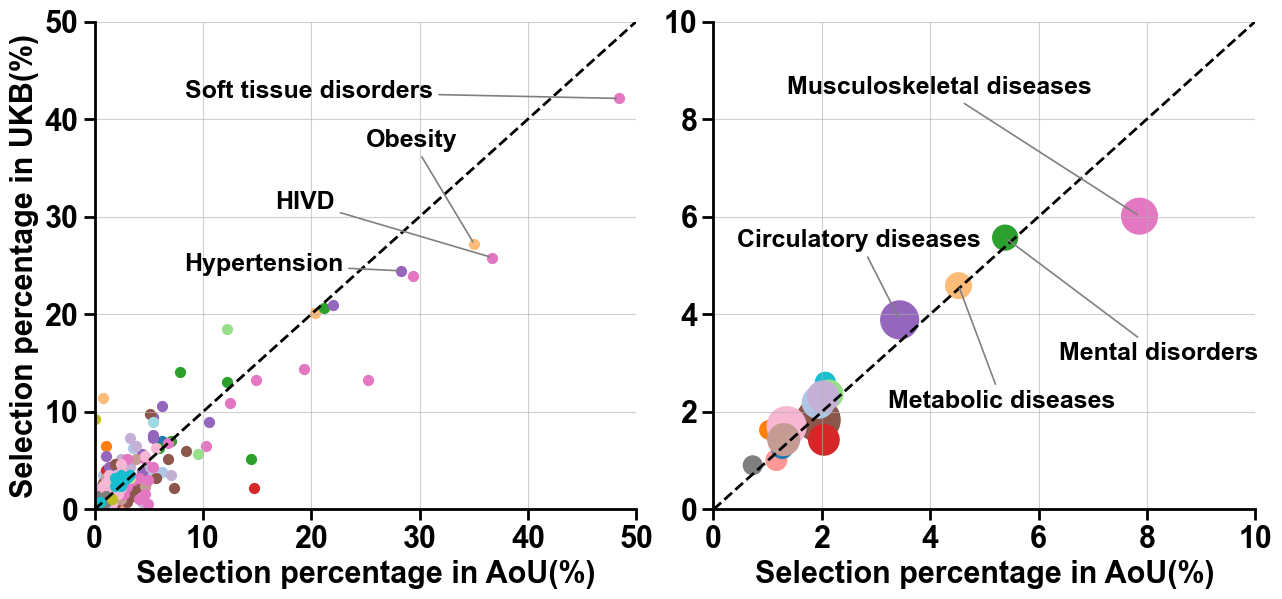

In [5]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import matplotlib

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
matplotlib.rcParams["font.family"] = "Arial"

ax = axes[0]

# Plot all traits, colored by chapter
for chapter in cm.icd_chapters.values():
    mask = trait_level_hub["chapter"] == chapter
    ax.scatter(
        trait_level_hub.loc[mask, "aou_hub_score"],
        trait_level_hub.loc[mask, "ukb_hub_score"],
        color=cm.chapter2color_map[chapter], s=50
    )

# Manually specify ICDs to annotate
icds_to_label = ["E66", "I10", "M51", "M79"]

# Filter to labeled ICDs present in trait_pivot
to_label = trait_level_hub[trait_level_hub["candidate_icd"].isin(icds_to_label)]

# Manual offsets (dx, dy) for each ICD label
manual_offsets = {
    "E66":  (-10, 10),
    "I10":  (-20, 0),
    "M51":  (-20, 5),
    "M79":  (-40, 0),
}

# Manually specify disease names for labeled ICDs
icd_to_name = {
    "E66": "Obesity",
    "I10": "Hypertension",
    "M51": "HIVD",
    "M79": "Soft tissue disorders",
}

for _, row in to_label.iterrows():
    dx, dy = manual_offsets.get(row["candidate_icd"], (0.1, 0.1))
    label = icd_to_name.get(row["candidate_icd"], row["candidate_icd"])  # fallback to ICD code if not found
    ax.annotate(
        label,
        xy=(row["aou_hub_score"], row["ukb_hub_score"]),
        xytext=(row["aou_hub_score"] + dx, row["ukb_hub_score"] + dy),
        fontsize=18, fontweight='bold',
        arrowprops=dict(arrowstyle="-", color="gray", lw=1.2),
        annotation_clip=False
    )

ax.plot([0, 50], [0, 50], color="black", linestyle="--", linewidth=2)
ax.set_ylim(0, 50)
ax.set_xlim(0, 50)
ax.set_yticks([0, 10, 20, 30, 40, 50])
ax.set_xticks([0, 10, 20, 30, 40, 50])

ax = axes[1]

ax.scatter(
    chapter_level_hub["aou_mean_chapter_hub_score"], 
    chapter_level_hub["ukb_mean_chapter_hub_score"],
    color=chapter_level_hub["chapter"].map(cm.chapter2color_map), 
    s=chapter_level_hub["n_traits"] * 20
)

# Manually specify ICDs to annotate
icds_to_label = ["Metabolic diseases", "Circulatory diseases", "Musculoskeletal diseases", "Mental disorders"]

to_label = chapter_level_hub[chapter_level_hub["chapter"].isin(icds_to_label)]

manual_offsets = {
    "Metabolic diseases":       (-1.3, -2.5),
    "Circulatory diseases":     (-3.0,  1.5),
    "Musculoskeletal diseases": (-6.5,  2.5),
    "Mental disorders":         ( 1.0, -2.5),
}

icd_to_name = {
    "IV":   "IV: Metabolic diseases",
    "IX":   "IX: Circulatory diseases",
    "XIII": "XIII: Musculoskeletal diseases",
    "V":    "V: Mental disorders",
}

for _, row in to_label.iterrows():
    dx, dy = manual_offsets.get(row["chapter"], (0.3, 0.3))
    label = icd_to_name.get(row["chapter"], row["chapter"])

    ax.annotate(
        label,
        xy=(row["aou_mean_chapter_hub_score"], row["ukb_mean_chapter_hub_score"]),
        xytext=(row["aou_mean_chapter_hub_score"] + dx, row["ukb_mean_chapter_hub_score"] + dy),
        fontsize=18, fontweight='bold',
        arrowprops=dict(arrowstyle="-", color="gray", lw=1.2),
        annotation_clip=False
    )

ax.plot([0, 10], [0, 10], color="black", linestyle="--", linewidth=2)
ax.set_ylim(0, 10)
ax.set_xlim(0, 10)
ax.set_yticks([0, 2, 4, 6, 8, 10])
ax.set_xticks([0, 2, 4, 6, 8, 10])

for i in range(2):
    ax = axes[i]
    ax.set_xlabel("Selection percentage in AoU(%)", fontsize=22, fontweight="bold")
    if i == 0:
        ax.set_ylabel("Selection percentage in UKB(%)", fontsize=22, fontweight="bold")

    ax.grid(alpha=0.6)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(2)
    ax.spines["bottom"].set_linewidth(2)

    ax.tick_params(axis="both", labelsize=22, length=8, width=2)
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontweight("bold")

plt.tight_layout()
plt.show()

In [6]:
from scipy.stats import spearmanr

# Spearman correlation: candidate-disease-level hub scores (AoU vs UKB)
rho_trait, p_trait = spearmanr(trait_level_hub["aou_hub_score"], trait_level_hub["ukb_hub_score"], nan_policy="omit")
print(f"Disease level (n = {len(trait_level_hub)}): Spearman r = {rho_trait:.3f}, P = {p_trait:.2e}")

# Spearman correlation: chapter-level mean hub scores (AoU vs UKB)
rho_chap, p_chap = spearmanr(chapter_level_hub["aou_mean_chapter_hub_score"], chapter_level_hub["ukb_mean_chapter_hub_score"], nan_policy="omit")
print(f"Chapter level (n = {len(chapter_level_hub)}): Spearman r = {rho_chap:.3f}, P = {p_chap:.2e}")

# Optional: write r in the bottom-right corner of each panel
axes[0].text(0.97, 0.04, f"Spearman r = {rho_trait:.2f}", transform=axes[0].transAxes,
             ha="right", va="bottom", fontsize=18, fontweight="bold")
axes[1].text(0.97, 0.04, f"Spearman r = {rho_chap:.2f}", transform=axes[1].transAxes,
             ha="right", va="bottom", fontsize=18, fontweight="bold")

Disease level (n = 368): Spearman r = 0.752, P = 3.46e-68
Chapter level (n = 16): Spearman r = 0.909, P = 1.10e-06


Text(0.97, 0.04, 'Spearman r = 0.91')

# (d) Within-chapter enrichment

In [7]:
def chapter_enrichment(matrix):
    # matrix: rows = target ICDs, columns = candidate PRS ICDs
    target_trait_chapters = np.array([cm.assign_chapter(icd) for icd in matrix.index])
    candidate_trait_chapters = np.array([cm.assign_chapter(icd) for icd in matrix.columns])

    n_candidate_traits = matrix.shape[1]  # total number of candidate traits

    records = []
    for chap in set(target_trait_chapters):
        row_mask = target_trait_chapters == chap
        col_mask = candidate_trait_chapters == chap

        # DataFrame -> use .iloc
        total_selected = matrix.iloc[row_mask, :].values.sum()
        within_selected = matrix.iloc[row_mask, col_mask].values.sum()

        assert total_selected == row_mask.sum() * 10, (
            f"{chap}: total_selected={total_selected}, expected={row_mask.sum() * 10}"
        )

        p_obs = within_selected / total_selected
        p_exp = col_mask.sum() / n_candidate_traits
        enrichment = p_obs / p_exp 
        log2_enrichment = np.log2(enrichment) 

        records.append({
            "chapter": chap,
            "p_obs": p_obs,
            "p_exp": p_exp,
            "enrichment": enrichment,
            "log2_enrichment": log2_enrichment,
            "n_targets": row_mask.sum(),
            "n_candidates": col_mask.sum(),
            "total_selected": total_selected,
            "within_selected": within_selected,
        })

    return pd.DataFrame(records)

aou_enrich = chapter_enrichment(aou_bmatrix)
ukb_enrich = chapter_enrichment(ukb_bmatrix)

# Merge AoU and UKB into one frame and enforce canonical chapter ordering
merged = aou_enrich.merge(ukb_enrich, on="chapter", suffixes=("_aou", "_ukb"))
merged["chapter_roman"] = merged["chapter"].map(cm.chapter2roman_map)

# Drop chapters with fewer than 5 target or candidate traits in either cohort
keep = ((merged["n_targets_aou"] >= 5) & (merged["n_candidates_aou"] >= 5)
        & (merged["n_targets_ukb"] >= 5) & (merged["n_candidates_ukb"] >= 5))
merged = merged[keep].reset_index(drop=True)

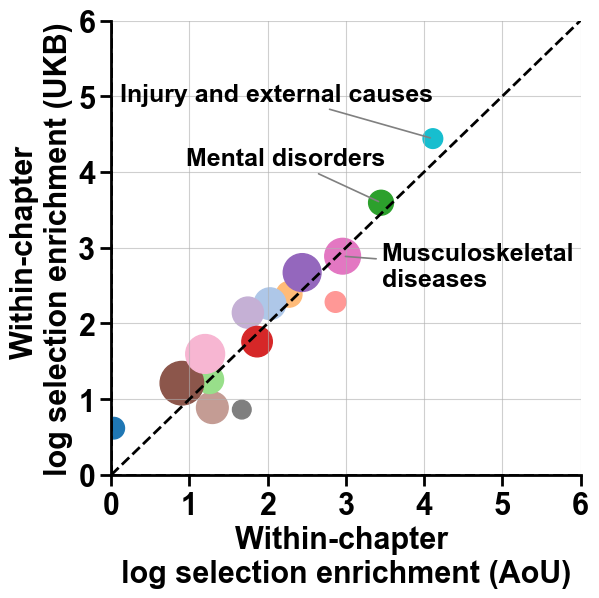

In [9]:
fig, ax = plt.subplots(figsize=(6, 6))
matplotlib.rcParams['font.family'] = 'Arial'

ax.scatter(
    merged["log2_enrichment_aou"],
    merged["log2_enrichment_ukb"],
    color=merged["chapter"].map(cm.chapter2color_map),   
    s=merged["n_targets_aou"] * 20
)

# Manually specify ICDs to annotate
chapters_to_label = [
    "Musculoskeletal diseases",
    "Mental disorders",
    "Injury and external causes",
]

to_label = merged[merged["chapter"].isin(chapters_to_label)].copy()

manual_offsets = {
    "Musculoskeletal diseases":    ( 0.5, -0.4),
    "Mental disorders":            (-2.5,  0.5),
    "Injury and external causes":  (-4.0,  0.5),
}

chapter_label_map = {
    "Musculoskeletal diseases":   "Musculoskeletal\ndiseases",
    "Mental disorders":           "Mental disorders",
    "Injury and external causes": "Injury and external causes",
}

for _, row in to_label.iterrows():
    chapter = row["chapter"]
    dx, dy = manual_offsets.get(chapter, (0.3, 0.3))
    text = ax.annotate(
        chapter_label_map.get(chapter, chapter),
        xy=(row["log2_enrichment_aou"], row["log2_enrichment_ukb"]),
        xytext=(row["log2_enrichment_aou"] + dx, row["log2_enrichment_ukb"] + dy),
        fontsize=18, fontweight='bold',
        arrowprops=dict(arrowstyle="-", color="gray", lw=1.2),
        annotation_clip=False
    )


ax.plot([0, 6], [0, 6], color="black", linestyle="--", linewidth=2)
ax.axvline(0, color="black", linestyle="--", linewidth=2)
ax.axhline(0, color="black", linestyle="--", linewidth=2)
ax.set_ylim(0, 6)
ax.set_xlim(0, 6)
ax.set_yticks([0, 1, 2, 3, 4, 5, 6]); ax.set_xticks([0, 1, 2, 3, 4, 5, 6])
ax.set_xlabel("Within-chapter \nlog selection enrichment (AoU)", fontsize=22, fontweight='bold')
ax.set_ylabel("Within-chapter \nlog selection enrichment (UKB)", fontsize=22, fontweight='bold')

ax.grid(alpha=0.6)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(2)
ax.spines["bottom"].set_linewidth(2)

ax.tick_params(axis="both", labelsize=22, length=8, width=2)
for label in ax.get_xticklabels() + ax.get_yticklabels():
    label.set_fontweight("bold")

plt.tight_layout()
plt.show()

In [10]:
spearman_r, spearman_p = spearmanr(merged["log2_enrichment_aou"], merged["log2_enrichment_ukb"])
print(spearman_r, spearman_p)

0.9029411764705882 1.677724370594156e-06


# (e) Best candidate PRS

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib

matplotlib.rcParams["font.family"] = "Arial"

def summarize_best_cross_trait(pmatrix, cohort_name, top_n=5): 
    best_icd = pmatrix.idxmax(axis=1) 
    
    df = pd.DataFrame({"target_icd": pmatrix.index, "best_icd": best_icd.values}) 
    df["is_self_best"] = df["target_icd"] == df["best_icd"] 
    
    n_total = len(df) 
    self_count = df["is_self_best"].sum() 
    self_pct = self_count / n_total * 100 
    other_df = df[~df["is_self_best"]].copy() 
    top_other = ( other_df["best_icd"] .value_counts() .head(top_n) .reset_index() ) 
    top_other.columns = ["category", "count"] 
    top_other["pct"] = top_other["count"] / n_total * 100 
    
    out_df = pd.concat([pd.DataFrame({"category": ["Self PRS"], "count": [self_count], "pct": [self_pct]}), top_other], ignore_index=True) 
    out_df["cohort"] = cohort_name 

    return out_df, df

In [12]:
aou_bar_df, aou_best_detail = summarize_best_cross_trait(aou_pmatrix, cohort_name="AOU", top_n=3)
ukb_bar_df, ukb_best_detail = summarize_best_cross_trait(ukb_pmatrix, cohort_name="UKB", top_n=3)

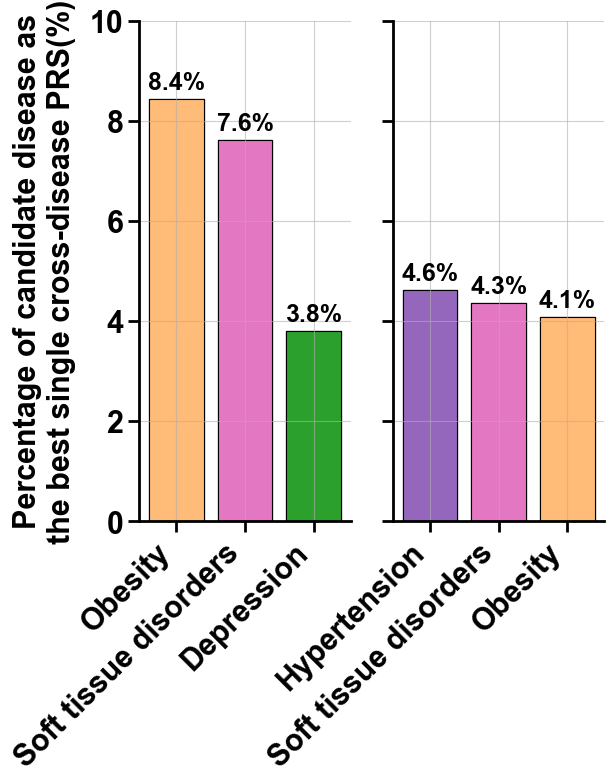

In [13]:
import matplotlib.pyplot as plt 
import matplotlib 

icd_to_name = { "E11": "T2D", 
                "I10": "Hypertension", 
                "M51": "Disc disorder", 
                "F32": "Depression", 
                "E66": "Obesity", 
                "M79": "Soft tissue disorders",
                "W19": "Unspecified fall",
                "F39": "Mood disorder"} 

matplotlib.rcParams["font.family"] = "Arial" 

fig, axes = plt.subplots(1, 2, figsize=(6, 6.5), sharey=True)
for ax, bar_df, cohort in zip(axes, [aou_bar_df, ukb_bar_df], ["AoU", "UKB"]): 

    bar_df = bar_df[bar_df["category"] != "Self PRS"].reset_index(drop=True)
    bar_colors = [] 
    labels = [] 
    for cat in bar_df["category"]: 
        if cat == "Self PRS": 
            bar_colors.append("#4C72B0") 
            labels.append("Self PRS") 
            
        else: 
            chapter = cm.assign_chapter(cat) 
            bar_colors.append(cm.chapter2color_map.get(chapter, "lightgray")) 
            disease = icd_to_name.get(cat, "") 
            labels.append(f"{disease}") 
            bars = ax.bar(bar_df["category"], bar_df["pct"], color=bar_colors, edgecolor="black", linewidth=0.8, width=0.8) 
 
    ax.set_xticks(range(len(bar_df))) 
    ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=14, fontweight="bold" ) 
            
    for i, row in bar_df.iterrows(): 
        ax.text(i, row["pct"] + 0.1, f"{row['pct']:.1f}%", ha="center", va="bottom", fontsize=18, fontweight="bold")
        ax.set_ylim(0, 10)
        ax.set_yticks([0, 2, 4, 6, 8, 10])

        ax.grid(alpha=0.6)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.spines["left"].set_linewidth(2)
        ax.spines["bottom"].set_linewidth(2)

        ax.tick_params(axis="both", labelsize=22, length=8, width=2)
        for label in ax.get_xticklabels() + ax.get_yticklabels():
            label.set_fontweight("bold")
        
        axes[0].set_ylabel("Percentage of candidate disease as\nthe best single cross-disease PRS(%)", fontsize=22, fontweight="bold", labelpad=10) 

# plt.tight_layout()          
plt.show()